# **1. Q-Table**

- Q는 "현재 상태에서 이 행동을 했을 때 앞으로 얼마나 유리한가"를 나타내는 행동 가치이다.
- Q-Table은 이 값을 표 형태로 저장한다.
- Q-Table은 정답표가 아니다. 에이전트가 보상을 경험하며 채우고 수정하는 표이다.

### **1-1. Q-Table의 한계**

- 로봇은 거리, 속도, 방향 등 연속적인 숫자를 받는다.
- 상태를 세밀하게 구분하면 조합이 매우 커지게 된다.
    - `예) 센서 3개를 각각 100단계로 구분하고, 행동이 4개뿐이라고 하더라도 100 * 100 * 100 * 4 = 4000000개의 Q값이 필요하다. 센서가 더 많아진다면 값이 더 커질 것이다.`

- 상태마다 숫자를 저장하는 대신 상태 > 신경망 > 각 행동의 Q값이라는 관계를 학습하는 것이 좋지 않겠나?
    - 처음 보는 상태도 비슷한 학습 경험을 활용해 Q값을 예측한다. -> 이를 ***함수 근사*** 라고 한다.

> 신경망이 언제나 정확한 것은 아니다. 학습 경험이 부족하거나 새로운 상황이 너무 다르면 잘못 에측할 수 있다.

![Q테이블 개념 및 한계](./images/ref/04_01.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from collections import deque
import random

In [2]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [4]:
### 수식이니까 가볍게 보고 넘어갈 코드
small = np.zeros((5, 2))
large_count = 100 ** 3 * 4
print('작은 미로 Q-Table 크기:', small.shape, '→', small.size, '개')
print('센서 3개를 100단계로 구분할 때:', f'{large_count:,}', '개')
print('float32로 저장할 때 약:', round(large_count * 4 / 1024**2, 2), 'MiB')

작은 미로 Q-Table 크기: (5, 2) → 10 개
센서 3개를 100단계로 구분할 때: 4,000,000 개
float32로 저장할 때 약: 15.26 MiB


In [5]:
### 예제 
x = torch.arange(1, 6, dtype=torch.float32).unsqueeze(1) # unsqueeze(1): 인덱스 1 위치에 차원 추가
print(x.shape)

y = x / 6.0
model = nn.Linear(1, 1) # 입력 1개, 출력 1개. wx + b 형태의 선형 회귀 모델. 학습할 매개변수는 w와 b
optimizer = optim.SGD(model.parameters(), lr=0.01) # 경사 하강법 최적화 알고리즘. 학습률 0.01

### 학습 루프
for epoch in range(1000):
    prediction = model(x) # 모델에 입력 x를 넣어 예측값 계산
    loss = ((prediction - y) ** 2).mean() # MSE. 오차 제곱의 평균을 손실로 계산
    optimizer.zero_grad() # 이전 단계에서 계산된 기울기 초기화
    loss.backward() # 역전파. 손실에 대한 기울기 계산
    optimizer.step() # 매개변수 업데이트. w와 b를 기울기에 따라 조정

torch.Size([5, 1])


In [6]:
### 학습 결과 확인
print('w, b: ', model.weight.item(), model.bias.item())
print('상태 2.5의 예측 가치: ', model(torch.tensor([[2.5]])).item()) # 학습이 어느 정도 됐고, 상태 2.5에 대한 예측 가치 확인을 해본다.

w, b:  0.16890689730644226 -0.008087950758635998
상태 2.5의 예측 가치:  0.4141792953014374


***
# **2. DQN**

### **2-1. DQN(Deep Q-Network)이 단순한 신경망 하나가 아닌 이유**

- 신경망에 상태를 넣고 Q값만 예측할 수 없다.
- 강화학습 데이터는 일반적인 사진 분류 데이터와 다르게 시간 순서대로 서로 비슷한 경험이 연속해서 발생한다.
- 학습 목표를 만드는 데 사용하는 Q값도 신경망이 추정하므로 목표 자체가 계속 바뀐다.

1. Q-Network: 현재 상태를 보고 각 행동의 Q점수를 예측한다. `예) [왼쪽=12.1, 오른쪽=15.4]라면 오른쪽이 더 좋다고 판단`
2. Experience Replay (경험 재생): 상태, 행동, 보상, 다음 상태, 종료 여부를 메모리에 모아 둔다. 학습할 때는 최근 경험 하나만 쓰지 않고 과거 경험을 무작위로 섞어서 뽑는다. 연속 경험 사이의 상관성을 완화하고 경험을 재사용할 수 있다.
3. Target Network(타깃 신경망): 학습하는 네트워크와 별도로 목표값 계산용 네트워크를 따로 둔다. 목표값이 매번 너무 급격히 움직이지 않도록 일정 주기마다 학습 네트워크의 가중치를 복사한다.

> Target Network는 잠시 고정된 정답지 역할이다. Replay Buffer는 과거 문제를 섞어 복습하는 문제은행과 비슷하다. Target Network가 실제 정답을 아는 것은 아니다. 역시 추정값을 제공할 뿐이다.

![DQN이란?](./images/ref/04_02.png)

### **2-2. 지도학습과 DQN 학습의 차이**

1. 지도학습
    - 입력: 숫자 x
    - 목표값: 미리 정한 x / 6 (위 예제 코드 참고)
    - 출력: 예측 숫자 1개
    - 학습: 손실 > 역전파 > 가중치 수정

2. DQN
    - 입력: 환경에서 관측한 상태
    - 목표값: 보상 + 할인된 다음 상태 가치
    - 출력: 각 이산 행동의 Q값
    - 학습: 손실 > 역전파 > 가중치 수정

> 이산 행동: 에이전트가 선택할 수 있는 행동이 정해진 개수로 구분되어 있는 것<br>
> 연속 행동: 일정한 범위 안에서 연속적인 값을 선택하는 행동. 예) 자동차 핸들 -2.0 ~ 2.0 조절<br>
> Q값: 현재 상태에서 특정 행동을 선택했을 때 앞으로 얻을 것으로 기대되는 누적 보상 (개념 자체가 다름)<br>
> -> 용어 헷갈리지 않도록 하기

![차이점 요약 이미지](./images/ref/04_03.png)


### **2-3. 예제에 사용할 CartPole 데이터 설명**

- 막대가 달린 수레. 막대가 넘어지지 않도록 수레를 왼쪽 또는 오른쪽으로 밀어 균형을 잡는 문제이다.
- 사람은 기울어진 방향을 보고 움직이지만, 에이전트는 처음에 방법을 모른다.
- 환경이 제공하는 관측값
    - 수레 위치: 수레가 가운데에서 얼마나 벗어났는가
    - 수레 속도: 어느 방향으로 얼마나 빠르게 움직이는가
    - 막대 각도: 막대가 어느 쪽으로 얼마나 기울어졌는가
    - 막대 각속도: 기울기가 얼마나 빨리 변하는가
- 행동은 0=왼쪽, 1=오른쪽 두 가지. 오래 버틸수록 매 스텝 보상을 쌓는다. 좋은 행동은 단순히 현재 기울기를 줄이는 행동이 아니라 장기적으로 균형을 오래 유지하는 행동이다.
- reset(): 새 시도를 시작
- step(action): 행동 후 (관측, 보상, terminated, truncated, info) 다섯 가지를 반환
    - terminated: 실패/성공 등 환경이 정의한 종료 조건에 도달
    - truncated: 시간 제한 등 외부 조건으로 시도가 끝남

```
pip install gymnasium
```

In [7]:
import gymnasium as gym

In [8]:
probe = gym.make('CartPole-v1')
obs, info = probe.reset(seed=SEED)
print('관측: ', obs, ' | 관측 공간: ', probe.observation_space)
print('행동 공간: ', probe.action_space)
next_obs, reward, terminated, truncated, info = probe.step(0)
print('한 단계 결과: ', reward, terminated, truncated)
probe.close()

관측:  [-0.03210652  0.01399132 -0.00327316 -0.01294995]  | 관측 공간:  Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
행동 공간:  Discrete(2)
한 단계 결과:  1.0 False False


### **2-4. Replay Buffer**

- 경험 저장소. 예) (상태 4개, 오른쪽, +1, 다음 상태 4개, False)

#### **2-4-1. 예제에 사용할 함수 작성**

In [9]:
### 
class ReplayBuffer:
    def __init__(self, capacity=30000):
        self.data = deque(maxlen=capacity)

    def add(self, s, a, r, ns, terminated):
        self.data.append((s, a, r, ns, terminated))

    def sample(self, batch_size):
        batch = random.sample(self.data, batch_size)
        s, a, r, ns, d = zip(*batch)
        return (torch.as_tensor(np.asarray(s),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(a,dtype=torch.long,device=DEVICE).unsqueeze(1),
                torch.as_tensor(r,dtype=torch.float32,device=DEVICE).unsqueeze(1),
                torch.as_tensor(np.asarray(ns),dtype=torch.float32,device=DEVICE),
                torch.as_tensor(d,dtype=torch.float32,device=DEVICE).unsqueeze(1))

    def __len__(self):
        return len(self.data)

In [10]:
### 
class QNetWork(nn.Module):
    def __init__(self, obs_dim=4, actions=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, actions)
        )

    # 순전파
    def forward(self, x):
        return self.net(x)

In [11]:
q_test = QNetWork().to(DEVICE)
q_test

QNetWork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [12]:
print(q_test(torch.zeros((3, 4), device=DEVICE)).shape)

torch.Size([3, 2])


```
현재 상태에서 오른쪽에 대한 행동의 신경망 예측이 Q=4라고 가정한다.
행동 후 보상 +1을 받았고, 타깃 신경망이 다음 상태의 최고 Q를 6이라고 예측했다면, 
할인율 0.9에서 목표는 1 + 0.9 * 6 = 6.4

현재 예측 4와 목표 6.4 사이의 차이가 있으므로, 신경망 가중치를 조금 수정해 오른쪽 행동의 Q예측이 목표에 가까워지게 한다.
```

In [13]:
def dqn_update(online, target, buffer, optimizer, batch_size=64, gamma=0.99, double=False):
    states, actions, rewards, next_states, terminated = buffer.sample(batch_size)

    # online(states)는 [batch, 2]. 선택 행동만 뽑아 [batch, 1]로 만든다.
    # gather(...): 신경망이 출력한 여러 행동 점수 중에서 실제로 선택했던 행동의 점수만 추출
    choosen_q = online(states).gather(1, actions)
    with torch.no_grad():
        if double:
            # 행동을 고른 다음 그 행동을 평가
            next_actions = online(next_states).argmax(dim=1, keepdim=True) 
            next_q = target(next_states).gather(1, next_actions) 

        else:
            # 다음 상태의 최대 Q값을 구함
            next_q = target(next_states).max(dim=1, keepdim=True).values
        # TD 목표값
        targets = rewards + gamma * (1 - terminated) * next_q
    loss = nn.functional.smooth_l1_loss(choosen_q, targets)
    optimizer.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(online.parameters(), 10.0)
    optimizer.step()
    return float(loss.item())

### **2-4-2. 예제: DQN 신경망을 학습시켜 에이전트가 스스로 적절한 행동을 선택하도록 만들어보기**

1. 구현 요구사항
    - CartPole-v1 환경 생성
    - Online Network와 Target Network 생성
    - Adam 옵티마이저, Replay Buffer 초기화
    - 초기에는 무작위 행동을 많이 선택하도록 구현
    - 학습이 진행될수록 ε값을 감소
    - 탐험하지 않을 때는 신경망이 예측한 Q값을 기준으로 행동 선택
    - 현재 상태, 행동, 보상, 다음 상태, 종료 여부를 Replay Buffer에 저장
    - Replay Buffer에 1000개 이상의 경험이 쌓이면 학습 시작
    - 4스탭마다 dqn_update() 실행
    - 500 스탭마다 online Network의 가중치를 Target Network에 복사

2. 학습 결과 기록
    - 총 250개 에피소드 학습
    - 에피소드별 누적 보상 저장
    - 50개 에피소드마다 최근 20개 에피소드의 평균 보상 출력

3. 학습 결과 시각화
    - 에피소드별 누적 보상
    - 최근 20개 에프소드의 이동평균 보상

In [14]:
def train_cartpole(episodes=250, double=False, seed=2026):
    # 난수 고정: 실행할 때마다 결과의 변동을 줄이기 위함
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    env = gym.make('CartPole-v1')
    env.action_space.seed(seed)

    # online: 실제 학습하는 모델 / target: 목표 Q값 계산에 사용하는 모델
    online = QNetWork().to(DEVICE)
    target = QNetWork().to(DEVICE)

    target.load_state_dict(online.state_dict())
    target.eval()

    optimizer = optim.Adam(online.parameters(), lr=5e-4)
    replay = ReplayBuffer()  # 경험(상태, 행동, 보상, 다음 상태, 종료 여부) 저장
    returns = []
    losses = []
    steps = 0

    # 에피소드마다 환경 초기화(환경은 조금씩 다르게 설정)
    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        total = 0.0

        for t in range(500):
            # 초반엔 무작위 행동을 많이 하게 한 후 스텝이 늘어나면 학습된 행동 활용하도록 함
            epsilon = max(0.05, 1.0 - steps / 12000)

            if random.random() < epsilon:
                action = env.action_space.sample()  # 무작위 행동
            else:
                with torch.no_grad():
                    tensor = torch.as_tensor(
                        state, dtype=torch.float32, device=DEVICE
                    ).unsqueeze(0)
                    # Q값이 가장 높은 행동 선택 
                    action = int(online(tensor).argmax(dim=1).item())

            # 행동 실행 후 다음 상태, 보상, 종료 여부 확인
            next_state, reward, terminated, truncated, _ = env.step(action)

            # 경험을 저장하고 다음 상태로 이동
            replay.add(state, action, reward, next_state, terminated)
            state = next_state
            total += reward
            steps += 1

            # 경험 1000개 이상 수집 후 4스텝마다 dqn_update()로 신경망 학습
            if len(replay) >= 1000 and steps % 4 == 0:
                losses.append(
                    dqn_update(online, target, replay, optimizer, double=double)
                )

            # 500스텝마다 online 가중치 target에 복사
            # 가중치를 동기화 시켜주는거임! 역전파 아님!!
            if steps % 500 == 0:
                target.load_state_dict(online.state_dict())

            # 막대가 쓰러지거나 최대 진행 시간에 도달하면 종료
            if terminated or truncated:
                break

        # 에피소드별 누적 보상 기록
        returns.append(total)  

        if (episode + 1) % 50 == 0:
            print(f"{episode+1:3d}회 | 최근 20회 평균 보상: {np.mean(returns[-20:]):.1f}")

    env.close()

    return online, returns, losses

![위 코드에서 알아야 할 것](./images/ref/04_04.png)

terminated는 환경의 종료 조건을 만족한 경우이고, truncated는 시간 제한 등으로 진행이 중단된 경우임. <br>
현재 코드에서는 에피소드 종료 판단에 둘 다 사용하지만, 경험 저장에는 terminated만 전달하고 있음

> 학습이 불안정하면 에피소드 수, 탐험률, 학습률 등 확인해봐야함

In [15]:
trained_q, train_returns, train_losses = train_cartpole(episodes=250)

 50회 | 최근 20회 평균 보상: 26.6
100회 | 최근 20회 평균 보상: 22.5
150회 | 최근 20회 평균 보상: 31.5
200회 | 최근 20회 평균 보상: 93.0
250회 | 최근 20회 평균 보상: 200.6


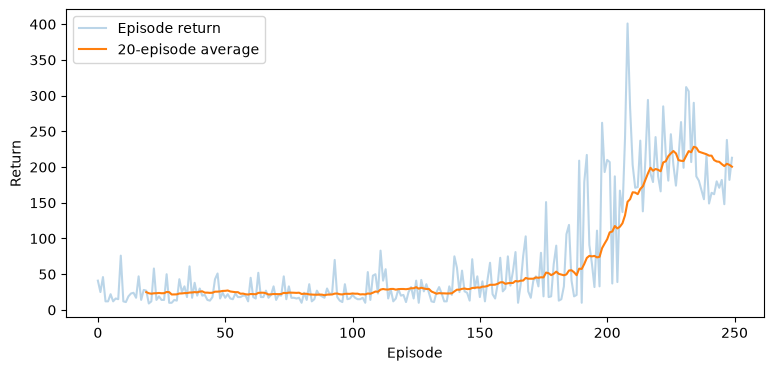

In [16]:
plt.figure(figsize=(9,4))
plt.plot(train_returns,alpha=.3,label='Episode return')
if len(train_returns)>=20:
    plt.plot(np.arange(19,len(train_returns)),np.convolve(train_returns,np.ones(20)/20,'valid'),label='20-episode average')
plt.xlabel('Episode');plt.ylabel('Return');plt.legend();plt.show()

### **2-4-3. 평가함수 만들기**
DQN 학습 시 무작위 행동이 필요하지만, 쳥가할땐 무작위 행동 제거해야함

: 학습은 경험저장과 학습을 하지만 평가에선 보상 측정만 수행하니까

평가에서 무작위 행동 없앤다해서 평가 결과가 항상 똑같은거 아님

In [17]:
def evaluate_cartpole(model, episode=10, seed=9000):
    env = gym.make('CartPole-v1')

    scores = []
    model.eval()

    for ep in range(episode):
        state, _ = env.reset(seed=seed + ep)
        total = 0

        while True:
            # 무작위 행동 없이 Q값이 가장 높은 행동 선택
            # 관측 4개 (1, 4)형태로 만듦
            with torch.no_grad():
                x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                action = int(model(x).argmax(dim=1).item())

            state, r, terminated, truncated, _ = env.step(action)
            total += r

            if terminated or truncated:
                break

        scores.append(total)

    env.close()
    return scores

![위 함수 핵심 코드](./images/ref/04_05.png)

In [18]:
scores = evaluate_cartpole(trained_q)

print("평가 점수:", scores)

print(f"평균 보상: {np.mean(scores):.1f}")
print(f"표준 편차: {np.std(scores):.1f}")

평가 점수: [221.0, 295.0, 210.0, 208.0, 245.0, 310.0, 237.0, 243.0, 227.0, 210.0]
평균 보상: 240.6
표준 편차: 33.6


> 학습이 진행될수록 에피소드별 누적 보상(Return)이 증가하고, 높은 보상이 안정적으로 유지된다면 학습이 잘 되고있다고 판단

> 학습 그래프가 좋아보이는것과 실제 모델이 잘 학습된건 다름 > evaluate_cartpole()로 평가

### **2-5. CartPole에서 학습이 잘 되고있는지 체크**
- 매 스텝마다 일반적으로 보상 +1
- 막대가 넘어지거나 수레가 허용 위치를 벗어나면 종료
- 최대 500 스텝까지 진행
- 한 에피소드의 최대 누적 보상은 500점

```
10 ~30: 거의 학습되지 않은 수준
30 ~ 100: 일부 행동 학습했을 가능성
100 ~ 200: 균형 유지 능력이 개선되는 단계
200 ~ 400: 좋은 성능
400 ~: 최대 성능
```

> DQN이 학습이 잘 되었다는건 Loss가 작아지는것만 의미하는게 아님

> 가장 중요한건 학습된 신경망이 실제 환경에서 좋은 행동을 선택하고, 여러번 평가했을 때 누적 보상을 안정적으로 얻는것임

![추가로 체크할 내용](./images/ref/04_06.png)

# **3. Policy Gradient (정책 경사법)**

```
게임에서 달리는 캐릭터 앞에 장애물이 있다면 : 가능한 행동은 0=대기, 1=점프로 두개 있음
- 학습 전: 점프 50%, 대기 50% 해놓았더니 결과가 어떻게될지 아직 잘 모름
- 여러번 시도 후 점프해서 장애물 피하는 좋은 결과를 경험하게 됨
- 그래서 비슷한 상황을 반복해서 학습하면? 점프 90%, 대기 10% 정도가 됨

DQN는 어떤 행동을 할지 딱 알려줌 > 점수가 나와서 높은 점수를 선택하게 됨(확률 아님)
PG는 합이 1이 되는데 확률이니까 10%를 선택하게 될수도 있음
```

> 정책은 '항상 점프'가 아님. 장애물이 멀면 대기가 좋을 수 있고, 가까우면 점프가 좋을 수 있음!

> 그래서 신경망은 현재 상태를 입력받아 행동별 확률을 출력하게 됨 > 이게 특징

![이해용 이미지](./images/ref/04_07.png)

- π(a|s): 상태 s일 때 행동 a를 선택할 확률
- θ: 신경망의 가중치. 즉, 학습하면서 바뀌는 숫자
- πθ(a|s): 신경망 가중치 θ가 정하는 행동 확률

> 확률 90%는 90%의 성공률과는 다름! 점프를 선택할 확률일뿐!!!


In [19]:
# 간단하게 계산만 하는~ 확률 비교하는~~
before = np.array([0.5, 0.5])
after  = np.array([0.1, 0.9])
for name, p in [('학습 전', before), ('학습 후(가상)', after)]:
    print(f'{name}: 대기 {p[0]*100:.0f}%, 점프 {p[1]*100:.0f}%, 합계 {p.sum():.1f}')

학습 전: 대기 50%, 점프 50%, 합계 1.0
학습 후(가상): 대기 10%, 점프 90%, 합계 1.0


### **3-1. DQN vs PG**
- DQN: 행동의 예상 점수를 계산하고 높은쪽으로 고름 (예시: 현재상태 > 신경망 > 대기[ Q=2, 점프=6])
- PG: 행동을 선택할 확률을 계산하고 그 확률에 따라 행동 뽑을 수 있음 (예시: 현재상태 > 신경망 > [대기 20%, 점프 80%])

> 둘 다 신경망 가중치를 실제로 학습하지만 출력의 의미와 학습 목표가 다름

> DQN에서 ε-greedy는 탐험을 위한 별도의 규칙이지만, PG는 행동 확률 자체를 배우는거임

> 정책 기반(PG)이라고 해서 항상 무작위 행동만 하는 것은 아니다. 평가할 때는 가장 확률이 높은 행동을 선택하기도 한다.

### **3-2. 학습의 순서**
1. 현재 상황 관측: 장애물 거리, 캐릭터 속도
2. 정책 신경망이 확률 계산: 대기 40%, 점프 60%
3. 행동 선택: 이번엔 점프
4. 실행: 장애물을 피했기 때문에 보상 +10 받음
5. 경험으로 학습 신호 만들기: 이번 행동이 좋은 결과와 연결되었다는 정보
6. 손실함수 계산/역전파/가중치 수정: 비슷한 상황에서 점프 확률을 높이는 방향으로 학습할 수 있음
7. 다시 게임 실행: 많은 경험을 반보하며 정책 개선


In [20]:
from torch.distributions import Categorical, Normal

In [21]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64),  # 입력 4개(상태) → 은닉층 뉴런 64개
            nn.Tanh(),               # 활성화 함수: 출력값을 -1 ~ 1 범위로 변환
            nn.Linear(64, n_actions) # 은닉층 64개 → 행동 2개의 로짓(Logit) 출력
        )

    def forward(self, x):
        return self.net(x)  # 행동별 로짓 반환 (아직 확률이 아님)

1. 신경망에서 데이터 이동하는 과정
    - ![코드 설명용](./images/ref/04_08.png)

2. 마지막 출력 2개 뭔데?
    - nn.Linear(64, 2)에서 나오는 2개의 숫자는 행동별 로짓(Logit)임
    - 로짓은 확률로 변환하기 전의 원시 점수 (DQN의 Q값과는 의미 다름!)

3. 중요한 차이점
    - ![차이점](./images/ref/04_09.png)
    - 지금 작성한 PolicyNet에는 Softmax가 없기 때문에 신경망이 확률을 직접 반환하는건 아님!

> 즉, 현재 PolicyNet의 출력 2개는 왼쪽과 오른쪽의 로짓이고, 이를 확률로 변환해야 PG의 행동 선택에 사용가능

In [22]:
policy_demo = PolicyNet().to(DEVICE)
state_demo = torch.tensor([[0.0, 0.1, 0.02, -0.03]], dtype=torch.float32, device=DEVICE)
logits = policy_demo(state_demo)
# Categorical: 0, 1처럼 이산행동의 확률 분포
# Normal: 연속 행동의 정규 분포
# logits는 확률 이전의 점수 > softmax를 적용하면 합계가 1인 확률 > Categorical로 실제 행동 추첨함
dist = Categorical(logits=logits)
a = dist.sample()

print('logits: ', logits.detach().cpu().numpy())
print('확률: ', dist.probs.detach().cpu().numpy())
print('행동: ', a.item(), 'log_prob: ', dist.log_prob(a).item())

logits:  [[ 0.2250176  -0.02445354]]
확률:  [[0.56204635 0.43795368]]
행동:  0 log_prob:  -0.5761709809303284


### **3-3. 한 에피소드가 끝난 뒤 학습**
- 순서: reset()하고 > 행동 샘플 주고 > step 진행하면 그 결과를 > (log_prob, reward)로 저장할 수 있고 > 종료 후 > G_t계산하고 > loss.backward()해서 > optimizer.step()을 하게 됨
- 근데 강화학습 자체는 미래 보상을 실제 에피소드 결과에서 계산하기 때문에 신경망으로 다음 상태가치를 부트스트랩하지는 않음!
- 그래서 에피소드 전체를 기다려야하기 때문에 결과 변동이 큰 편임!

- 만약에 예를 들어: 보상이 [1, 1, 1]로 3개가 들어왔다 치면, 할인률이 γ=0.9라면! 마지막 시점에선 `G₂=1, G₁=1+0.9*1=1.9, G₀=1+0.9*1.9=2.71`으로 계산됨
    - 즉 첫 행동은 이후 보상까지 반영을 한다는 얘기임

In [23]:
# 위 내용을 함수로 만든거
def discounted_returns(rewards,gamma=0.99):
    out=[]; running=0.0
    for r in reversed(rewards):
        running=float(r)+gamma*running
        out.append(running)
    return list(reversed(out))
print('예시:',discounted_returns([1,1,1],gamma=0.9))

예시: [2.71, 1.9, 1.0]


### 추가: DQN vs REINFORCE (Policy Gradient) 비교

| 구분 | DQN | REINFORCE (PG) |
|---|---|---|
| 저장 | Replay Buffer | 현재 한 판의 logps, rewards |
| 학습 | 일정 스탭마다 | 한 판 종료 후 |
| 학습 방식 | Q값 예측 개선 | 행동 선택 확률 개선 |
| 과거 경험 재사용 | O | X (기본 REINFORCE) |
| 학습 시점 | 일정 스텝마다 | 에피소드 종료 후 |
| 학습 데이터 | Buffer에서 무작위 샘플링 | 완료된 에피소드 |

In [24]:
# CartPole을 직접 플레이하면서 보상을 수집하고, 에피소드가 끝날 때마다 그 결과로 행동 선택 확률을 학습시키는 함수
def train_reinforce(episodes=250, seed=2026, gamma=0.99, lr=1e-3):
    torch.manual_seed(seed)
    env = gym.make('CartPole-v1')
    net = PolicyNet().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    scores = []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        logps = []
        rewards = []
        for t in range(500):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            dist = Categorical(logits=net(x))
            a = dist.sample()
            next_state, reward, terminated, truncated, _ = env.step(int(a.item()))

            # 선택한 행동의 로그 확률 저장
            # why? 계산하기 편하라고!
            # : 로그확률 사용하면 선택한 행동의 확률을 높이거나 낮추기 위한 신경망의 기울기 계산하기 편리해서!!
            logps.append(dist.log_prob(a).squeeze())
            rewards.append(float(reward))
            state = next_state

            if terminated or truncated: break

        G = torch.tensor(discounted_returns(rewards, gamma), dtype=torch.float32, device=DEVICE)
        if len(G) > 1:
            # 정규화 시킴~
            G = (G - G.mean()) / (G.std(unbiased=False)+1e-8)
        loss = -(torch.stack(logps) * G).sum()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scores.append(sum(rewards))

        if (ep+1)%30==0:print(f'REINFORCE {ep+1}/{episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}')

    env.close()
    return net, scores

![로그확률 사용 이유](./images/ref/04_10.png)

REINFORCE 30/250 | 최근 20회 평균 23.2
REINFORCE 60/250 | 최근 20회 평균 29.8
REINFORCE 90/250 | 최근 20회 평균 32.9
REINFORCE 120/250 | 최근 20회 평균 38.5
REINFORCE 150/250 | 최근 20회 평균 47.0
REINFORCE 180/250 | 최근 20회 평균 73.0
REINFORCE 210/250 | 최근 20회 평균 77.8
REINFORCE 240/250 | 최근 20회 평균 140.6


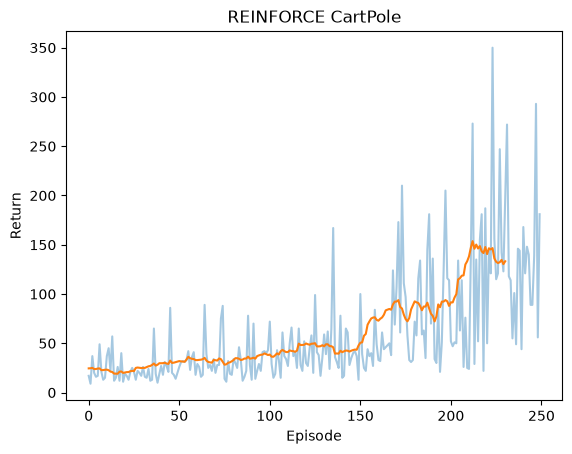

In [25]:
reinforce_model,reinforce_scores=train_reinforce(episodes=250)
plt.plot(reinforce_scores,alpha=.4)
if len(reinforce_scores)>=20:plt.plot(np.convolve(reinforce_scores,np.ones(20)/20,mode='valid'))
plt.title('REINFORCE CartPole');plt.xlabel('Episode');plt.ylabel('Return');plt.show()

# **4. Actor-Critic**
```
1. 캐릭터가 한 판을 끝까지 플레이함
2. 어떤 행동을 했고, 어떤 보상을 받았는지 기록
3. 그 시점 이후 얻은 보상(리턴)을 이용해 행동 확률을 조정
```
- 위 내용이 REINSORCE 핵심임
- 성공에 이르는 과정의 행동들을 학습에 반영(예시: 5번 점프하고 스테이지를 모두 클리어 함)
- 한 판이 끝나야 업데이트하는 기본형의 경우 보상 변동이 커서 학습이 불안정할 수 있음
- 잘했는지 판단하는 기준 부족함

- Actor: 지금 어떤 행동을 할지 정함 (예시: 점프 70%, 대기 30%)
- Critic: 현재 상황이 앞으로 얼마나 유리한지 평가 (예시: V(s)=5)

> 이 Critic이 예상보다 결과가 좋으면 : 선택한 행동의 확률을 높이는 학습 신호를 보냄

> 하지만 예상보다 결과가 나쁘면 : 선택한 행동의 확률을 낮추는 학습 신호를 보냄

```
장애물 피하기 게임
1. 캐릭터가 앞에 장애물이 나타남 -> 이게 상태임 State
2. Actor가 점프 70%, 대기 30#를 출력하고 행동을 하나 뽑음(두 합이 1이 되어야함) -> 이게 정책임 Policy
3. Critic은 현재 상황에서 앞으로 얻을 할인된 보상의 기대값을 예측함 (예시: V(s) = 4)
4. 실제로 행동한 뒤 보상 r과 다음 상태 s` 관찰함
5. Critic의 새 예측을 이용해 TD 오차 δ를 계사나고, Actor와 Critic을 각각 학습
```

> Critic의 예측은 정답이 아니라!! 학습 중이 추정치임. 평가도 틀릴 수 있음~!

> Critic이 정답 알고있는거 아님, 경험을 통해 예측을 고쳐나가는ㄴ것!!! -> 이게 좀 더 정확히 얘기한거니 기억~~


### 다시 개념 잡기
1. Actor의 출력
- 상태 s에서 행동 a를 선택할 확률을 출력함
- 확률 70%라는 말은 무조건 점프한다는 뜻 아님!
- DQN의 Q(s, a)는 행동별 가치를 말하는거고, Actor의 π(a|s)는 행동별 확률이므로 서로 다름!!!

2. Critic의 출력
- 상태 가치 V(s)를 출력함
- 현재 상태에서 정책을 따를 때 앞으로 얻을 할인된 보상의 기대값

$$
\delta = r + \gamma(1-done)V(s') - V(s)
$$

> $\delta$는 TD 오차. 새로 계산한 TD 목표 - Critic이 이전에 예측한 현재 가치


- 게임이 끝나지 않았다면(done=0) > 위 수식에서 done에 0 넣으면 > δ = r + γV(s') - V(s)
- 게임이 끝났다면(done=1)  > 위 수식에서 done에 1 넣으면 > δ = r - V(s)

```
게임이 아직 끝나지 않았고 + 아래 내용 참고해서 재미로~ 계산해봄
- 현재 가치 V(s) = 4
- 점프 직후 보상 r = 1
- 다음 상태 가치 V(s`) = 6
- 할인율 = 0.9
- done = 0
```

- TD 목표값 계산 = $r + \gamma(1-done)V(s')$ = 6.4
- δ값 = 6.4 - 4 = 2.4

> Critic이 예상한 4보다 TD 목표 6.4가 높음. Actor는 방금 선택한 점프의 확률을 높이는 방향으로 생각할거고, Critic은 4라는 예측을 6.4에 가깝게 만드는 방향으로 학습하게 됨

> 중요한건 2.4가 나오더라도 확률이 2.4% 증가한다는거 절대 아님. 실제 변화량은 신경망과 학습률에 따라 달라짐. Critic의 예측이 부정확할 수 있기때문에 정답이 아니라 학습 신호임!!

![개념잡기 내용 총정리](./images/ref/04_11.png)

$$
L_{actor}=-\log\pi(a|s)\,\mathrm{stopgrad}(\delta)
$$

$$
L_{critic}=(V(s)-\mathrm{stopgrad}(r+\gamma(1-done)V(s')))^2
$$

- stopgrad는 해당 값을 상수처럼 취급해 그 경로로 역전파하지 않는다는 의미임(이건 파이썬의 detach(), torch.no_grad()와 같은 의미)

```
Loss: 무엇을 얼마나 개선해야 하는지 나타내는 학습 목적 함수
Backward: Loss를 기준으로 각 가중치의 기울기 계산
Optimizer: 계산한 기울기를 사용해 실제 가중치 수정
```
![Actor Loss](./images/ref/04_12.png)

부호 -붙이는건 로그함수가 음수를 내놓으니까!

![Critic Loss](./images/ref/04_13.png)

제곱하는 이유는 음수가 나왔을 떄 양수로 변환하기 위헤! 줄어들면 안되니까!

![stopgrad](./images/ref/04_14.png)

![최종 수식 정리](./images/ref/04_15.png)

In [26]:
# TD오차 구하는 함수 = 그냥 예제용으로 쓴거임
def td_error(value, reward, next_value, gamma=0.9, done=False):
    target = reward + gamma * (1 - int(done)) * next_value
    delta = target - value
    return target, delta

cases = [
    ("예상보다 좋음", 4, 1, 6, 0.9, False),
    ("예상보다 나쁨", 5, 2, 4, 0.5, False),
    ("종료 상태", 4, 1, 100, 0.9, True),
]
for name, v, r, next_v, gamma, done in cases:
    target, delta = td_error(v, r, next_v, gamma, done)
    print(f"{name}: TD 목표={target:.2f}, 현재 예측={v:.2f}, δ={delta:+.2f}")

예상보다 좋음: TD 목표=6.40, 현재 예측=4.00, δ=+2.40
예상보다 나쁨: TD 목표=4.00, 현재 예측=5.00, δ=-1.00
종료 상태: TD 목표=1.00, 현재 예측=4.00, δ=-3.00


In [27]:

# Actor-Critic 신경망 정의
# 하나의 상태(State)를 입력받아 다음 두 가지 결과를 출력하는 모델
# 1. Actor: 각 행동의 선택 점수(logits)
# 2. Critic: 현재 상태의 가치 V(s)

class ActorCriticNet(nn.Module):

    # 신경망의 구조를 처음 설정하는 초기화 함수
    # obs_dim=4   : 입력 상태를 구성하는 숫자의 개수 (CartPole은 4개)
    # n_actions=2 : 선택 가능한 행동의 개수 (CartPole은 왼쪽/오른쪽 2개)
    def __init__(self, obs_dim=4, n_actions=2):

        # 부모 클래스(nn.Module)의 초기화 기능 실행 : PyTorch가 신경망의 가중치와 계층을 관리할 수 있도록 함
        super().__init__()

        # Actor와 Critic이 공통으로 사용하는 신경망 : 입력된 상태를 학습에 사용할 특징으로 변환
        self.body = nn.Sequential(

            # 입력 숫자 4개를 받아 특징값 128개로 변환 -> 128은 은닉층의 뉴런 개수이며, 직접 설정한 값
            nn.Linear(obs_dim, 128),

            # 활성화 함수: -1 ~ 1 범위로 출력값을 변환 (신경망이 비선형 관계를 학습할 수 있도록 함)
            nn.Tanh()
        )

        # Actor 출력층
        # 공통 특징값 128개를 받아 행동별 점수 2개 출력, 이 값은 확률이 아닌 logits(원시 점수)
        self.actor = nn.Linear(128, n_actions)

        # Critic 출력층
        # 공통 특징값 128개를 받아 상태 가치 V(s) 1개 출력
        self.critic = nn.Linear(128, 1)

    # 신경망에 입력값이 들어왔을 때 실행되는 순전파 함수
    # x: 환경에서 관측한 현재 상태
    def forward(self, x):

        # 현재 상태를 공통 신경망에 통과시켜 특징 추출  예: (4,) → (128,)
        h = self.body(x)

        # Actor: 행동별 점수 출력 → (2,)
        # Critic: 상태 가치 출력 → (1,)
        # squeeze(-1): Critic 출력의 마지막 크기 1인 차원 제거 예: (1,) → ()
        return self.actor(h), self.critic(h).squeeze(-1)


In [28]:
ac_demo = ActorCriticNet().to(DEVICE)
lg, val = ac_demo(state_demo)

print("Actor logits:", lg.shape)
print("Critic V(s):", val.shape)

Actor logits: torch.Size([1, 2])
Critic V(s): torch.Size([1])


In [29]:
import torch.nn.functional as F

In [30]:
ac = ActorCriticNet().to(DEVICE)
opt = optim.Adam(ac.parameters(), lr=1e-3)
s = torch.zeros((1, 4), device=DEVICE)
s2 = torch.tensor([[0.02, 0.1, -0.03, 0.02]], device=DEVICE)

logits, value = ac(s)
dist = Categorical(logits=logits)
a = dist.sample()

# 다음 상태가치로 만든 목표가 역전파가 되지 않도록.. 상수로 넣을것들을 계싼할 수 있도로 만듦
with torch.no_grad():
    _, next_value = ac(s2)
    td_target = torch.tensor([1.0], device=DEVICE) + 0.99*next_value

advantage = td_target - value
actor_loss = -(dist.log_prob(a) * advantage.detach()).mean() # 뭐 크리틱으로 역전퐈되는거 막으려고 detach()
critic_loss = F.mse_loss(value, td_target)
loss = actor_loss + 0.5 * critic_loss
opt.zero_grad()
loss.backward()
opt.step()
print('선택 행동:',a.item(),'TD 목표:',td_target.item(),'Advantage:',advantage.item(),'Loss:',loss.item())

선택 행동: 0 TD 목표: 1.0370668172836304 Advantage: 0.9830765724182129 Loss: 1.2196718454360962


### **4-1. Advantage**
```
A(s,a) = Q(s,a) - V(s)
```
- Q: 특정 행동의 예상 가치
- V: 그 상태에서 정책을 따를 때 평균적인 예상 가치
- Actor-Critic 코드에선 `r + γV(s') - V(s)` 같은 TD 오차를 Advantage의 추정값으로 사용
- Advantage는 받은 보상 r이 아님! 기대와 비교한 차이임

In [31]:
expected = 5.0
for name, estimated_action_value in [('점프', 8.0), ('대기', 3.0)]:
    advantage = estimated_action_value - expected
    print(f'{name}: 행동가치 {estimated_action_value:.1f} - 상태가치 {expected:.1f} = Advantage {advantage:+.1f}')

점프: 행동가치 8.0 - 상태가치 5.0 = Advantage +3.0
대기: 행동가치 3.0 - 상태가치 5.0 = Advantage -2.0


### **4-2. REINFORCE CartPole을 Actor-Critic으로 변경해보기**
- REINFORCE는 에피소드가 끝난 뒤 할인 리턴을 계산했지만, Actor-Critic은 매 스템 TD오차로 업데이트함
- PolicyNet 대신 Actor의 logits 2개 + Critic의 상태 가치 1개를 출력하는 ActorCriticNet 사용
- 학습 보상 곡선을 REINFORCE와 비교함

#### 문제는
1. ActorCriticNet을 이용해 행동 확률과 상태 가치 V(s)를 출력
2. Categorical(logits=logits)로 행동을 샘플링하고 환경에서 한 스탭을 실행
3. 250개 에피소드동안 학습하고, 각 에피소드 보상과 최근 20회 이동평균을 그림
4. 이미 학습한 reinforce_scores와 두 학습 곡선 비교


In [32]:
plt.rcParams["font.family"] = "Malgun Gothic"

In [33]:
# 평균 낮게 나와서 gamma를 0.9로 낮춤 (원래는 0.99)
# lr를 2e-3으로 설정 (원래는 7e-3) -> 이건 강사님 수업에만 그렇게 쓰고 나는 7e-3으로 계속 사용
def train_actor_critic_answer(episodes=250, seed=206, gamma=0.9, lr=7e-3):
    torch.manual_seed(seed)
    env = gym.make("CartPole-v1")
    model = ActorCriticNet().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        score = 0.0

        for t in range(500):
            x = torch.tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits, value = model(x) # Actor의 logits과 Critic의 value를 반환
            dist = Categorical(logits=logits)
            action = dist.sample() # 0이 나오면 왼쪽, 1이 나오면 오른쪽
            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

            with torch.no_grad():
                nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                _, next_value = model(nx)
                td_target = torch.tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

            delta = td_target - value # TD 오차 계산
            actor_loss = -(dist.log_prob(action) * delta.detach()).mean()
            critic_loss = F.mse_loss(value, td_target)
            loss = actor_loss + 0.5 * critic_loss

            # 학습진행
            optimizer.zero_grad()
            loss.backward()
            # 기울기 폭주 막음
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            score += float(reward)
            state = next_state
            if terminated or truncated:
                break

        scores.append(score)
        if (ep + 1) % 30 == 0:
            print(f"Actor-Critic {ep + 1} / {episodes} | 최근 20회 평균 {np.mean(scores[-20:]):.1f}")

    env.close()
    return model, scores

Actor-Critic 30 / 250 | 최근 20회 평균 9.5
Actor-Critic 60 / 250 | 최근 20회 평균 9.6
Actor-Critic 90 / 250 | 최근 20회 평균 9.4
Actor-Critic 120 / 250 | 최근 20회 평균 9.8
Actor-Critic 150 / 250 | 최근 20회 평균 24.5
Actor-Critic 180 / 250 | 최근 20회 평균 41.4
Actor-Critic 210 / 250 | 최근 20회 평균 63.6
Actor-Critic 240 / 250 | 최근 20회 평균 86.8


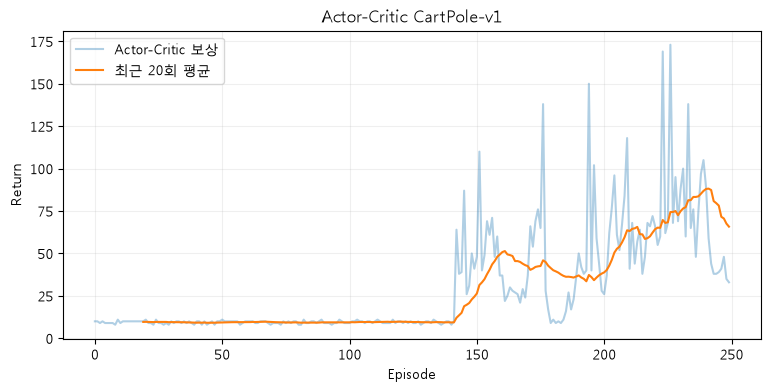

In [34]:
ac_cartpole_model, ac_cartpole_scores = train_actor_critic_answer()
plt.figure(figsize=(9, 4))
plt.plot(ac_cartpole_scores, alpha=0.35, label='Actor-Critic 보상')
if len(ac_cartpole_scores) >= 20:
    ma = np.convolve(ac_cartpole_scores, np.ones(20)/20, mode='valid')
    plt.plot(np.arange(19, len(ac_cartpole_scores)), ma, label='최근 20회 평균')
plt.xlabel('Episode'); plt.ylabel('Return'); plt.title('Actor-Critic CartPole-v1')
plt.legend(); plt.grid(alpha=0.2); plt.show()

In [35]:
if 'reinforce_scores' in globals():
    print('살아있음')

살아있음


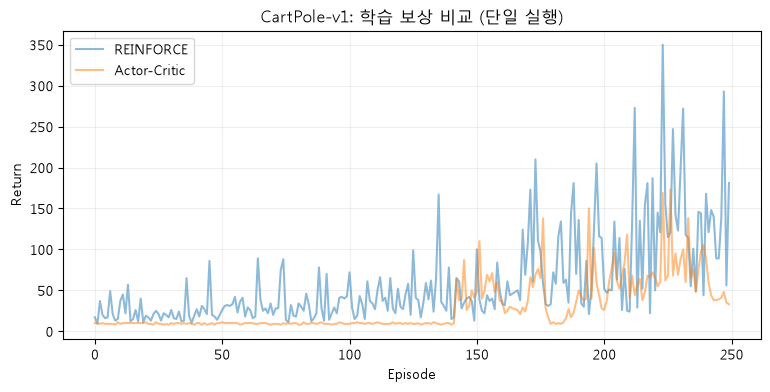

최근 20회 평균 REINFORCE: 133.2
최근 20회 평균 Actor-Critic: 65.8


In [36]:
if 'reinforce_scores' in globals():
    plt.figure(figsize=(9, 4))
    plt.plot(reinforce_scores, alpha=0.5, label='REINFORCE')
    plt.plot(ac_cartpole_scores, alpha=0.5, label='Actor-Critic')
    plt.xlabel('Episode'); plt.ylabel('Return')
    plt.title('CartPole-v1: 학습 보상 비교 (단일 실행)')
    plt.legend(); plt.grid(alpha=0.2); plt.show()
    print('최근 20회 평균 REINFORCE:', round(float(np.mean(reinforce_scores[-20:])), 1))
    print('최근 20회 평균 Actor-Critic:', round(float(np.mean(ac_cartpole_scores[-20:])), 1))

### 4-3. REINFORCE vs Actor-Critic 학습 결과 비교

1. REINFORCE 학습 결과
- 에피소드가 끝난 뒤 누적보상을 계산
- 실제 경험에서 얻은 리턴(보상)을 사용해 정책을 업데이트
- 리턴의 분산은 클 수 있지만, Critic을 사용하지 않으므로 구현이 단순함(가치 예측 오차에 영향 없음)

2. Actor-Critic 학습 결과
- 매 스탭마다 TD 오차를 계산하여 정책을 업데이트
- Critic이 상태의 가치 예측을 이용해서 Actor 학습
- Critic의 예측이 부정확하면 Actor 학습에 영향을 줄 수 있음

#### Actor-Critic의 성능을 높이려면?
- 학습 횟수를 늘리고, 학습률을 낮춤

# **5. Actor-Critic을 이용한 달 착륙 AI 개발**

Gymnasium을 이용해 우주선이 스스로 엔진을 제어하고 안전하게 착륙하도록 학습하는 강화학습 시스템 개발

### **5-1. 프로젝트 시나리오**
- 달 표면에 착륙할 우주선은 처음엔 엔진을 언제 사용해야하는지 알 수 없음
- 너무 빠르게 하강하면 추락하고, 좌우 균형을 잡지 못하면 착륙 지점을 벗어날 수 있음
    - 우주선의 현재 위치와 속도를 분석
    - 우주선읙 기울기와 회전 속도 확인
    - 엔진을 사용하거나 사용하지 않는 행동을 선택
    - 행동 결과로 받은 보상을 이용해 Actor와 Critic을 학습
    - 반복 학습을 통해 안전한 착륙 시도
- 그래서 우주선은 시행착오를 통해 안전하게 착륙하는 방법을 학습해야 함

### **5-2. 개발 환경**
- Gymnasium의 LunarLander-v3 환경 사용
```
python -m pip install "gymnasium[box2d]"
```

### **5-3. 상태 데이터**
- LunarLander-v3 매 스텝마다 8개의 숫자로 구성된 상태 벡터를 반환
```
인덱스 기준 값 설명

0 : 착륙 지점을 기준으로 한 좌우 위치
1 : 착륙 지점을 기준으로 한 높이
2 : 좌우 속도
3 : 수직 속도
4 : 우주선 기울기
5 : 우주선 회전 속도
6 : 왼쪽 착륙 다리가 지면에 닿았는지 여부 (0: 닿지 않음, 1: 닿았음)
7 : 오른쪽 착륙 다리가 지면에 닿았는지 여부 (0: 닿지 않음, 1: 닿았음)

값들은 정규화된 값임
```

### **5-4. 행동 데이터**
```
0: 엔진 사용하지 않음 - 중력에 따라 자연스럽게 이동
1: 왼쪽 보조 엔진 - 우주선의 자세와 이동에 영향
2: 주 엔진 - 주로 하강 속도를 제어하는데 사용
3: 오른쪽 보조 엔진 - 우주선의 자세와 이동에 영향
```

### **5-5. 보상 데이터**
- LunarLander는 단순히 착륙 성공과 실패만 평가하지 않음
- 착륙 지점까지의 거리, 속도, 기울기, 착륙 다리 접촉, 엔진 사용량 등을 함께 고려
    - 착륙 시점에 가까워질 때
    - 이동 속도가 줄어들 때
    - 우주선의 기울기가 커질때
    - 착륙 다리가 지면에 닿았을 때
    - 엔진 사용량이 적을 때
    - 보조 엔진 사용량이 적을 때
    - 추락할 때: -100
    - 안전하게 착륙할 때: +100

최대한 보상을 얻도록 우주선이 학습해야 함<br>
즉, 안전하게 착륙하고 엔진 사용량을 최소화하며 이동 속도를 줄이는 방향으로 행동을 선택하도록 학습해야 함<Br>
이를 위해 Actor-Critic 알고리즘을 사용하여 우주선의 행동 정책과 상태 가치를 동시에 학습함

### **5-6. 여기서부터 풀이**

In [37]:
# continuous=False: 이산 행동 공간 (기본값은 False) ↔ continuous=True: 연속 행동 공간 : 사용 안해도 ㄱㅊ
env = gym.make("LunarLander-v3", continuous=False)
state, info = env.reset(seed=2026)

print('상태 공간:', env.observation_space)
print('행동 공간:', env.action_space)
print('상태 shape:', state.shape)
print('행동 수:', env.action_space)

상태 공간: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
행동 공간: Discrete(4)
상태 shape: (8,)
행동 수: Discrete(4)


### MDP의 구성
- 상태 s: 우주선의 위치, 속도, 기울기, 착륙 다리 접촉 상태
- 행동 a: 네가지 엔진 선택
- 보상 r: 착륙 성공 시 보상, 충돌 시 패널티, 안정성, 연료 사용등의 결과
- 상태 전이 확률 P: 현재 상태와 행동에 따라 다음 상태로 전이될 확률 (물리 시뮬레이터가 행동에 따라 다음 상태를 계산)
- 할인율 γ: 미래 보상의 현재 가치에 대한 중요도를 나타내는 값 (미래 보상을 현재 보상에 얼마나 반영할지 계산)

### Actor와 Critic 의 역할
- Actor: π(a|s)라는 정책 학습. '이 상태에서 각 행동을 얼마나 자주 선택할까?'를 결정
- Critic: V(s)를 학습. '현재 상태에서 앞으로 받을 할인 보상은 얼마나 될까?'를 예측

### TD 목표

$
y_t=r_{t+1}+\gamma(1-\mathrm{terminated})V(s_{t+1})
$

- r: 이번 행동으로 실제 받은 보상
- γ V(s'): 다음 상태에서 앞으로 받을 보상에 대한 현재 추정
- terminated=True: 다음 상태의 가치를 더하지 않음

### TD 오차(델타)

$
\delta_t=y_t-V(s_t)
$

- δ값 > 0: 예상보다 실제 한 스템 결과가 좋음(보상이 더 큼) > 선택한 행동을 강화할 신호
- δ값 < 0: 예상보다 실제 한 스템 결과가 나쁨(보상이 더 작음) > 선택한 행동을 약화할 신호

> Critic이 틀릴 수 있기 때문에 δ는 완벽한 정답이 아니다


### Actor Loss

$
L_{actor}=-\log\pi(a_t|s_t)\,\mathrm{stopgrad}(\delta_t)
$

- 파이토치에서 log_prob(action)으로 사용: 이건 실제로 선택한 행동의 로그 확률을 의미
- delta.detach()사용: actor가 critic의 파라미터를 업데이트하지 않도록 함(TD 오차 역전파 경로로 직접 바꾸지 못하게 막음)
- stopgrad는 델타값을 고정하여 Critic의 학습에 영향을 주지 않도록 함

>즉, Actor는 Critic의 예측 오차를 신호로 사용하지만 Critic의 파라미터를 업데이트하지 않음!

### Critic Loss

$
L_{critic}=(V(s_t)-\mathrm{stopgrad}(y_t))^2
$

- stopgrad는 TD 목표를 고정하여 Critic의 학습에만 영향을 주도록 함
- TD 목표는 실제 보상과 다음 상태 가치의 합으로 계산되며, Critic이 이를 학습하도록 함

> 현재 가치 예측이 TD 목표에 가까워지도록 평균제곱오차(MSE)를 최소화

### 전체 Loss

$
L=L_{actor}+\beta L_{critic}-\eta H(\pi(\cdot|s))
$

- 전체 Loss는 Actor Loss와 Critic Loss를 합산하고, 정책 엔트로피를 통해 탐험을 장려
- β는 Critic Loss의 가중치, $\eta$는 엔트로피 항의 가중치를 의미
- 정책 엔트로피 $H(\pi(\cdot|s))$는 정책의 불확실성을 측정하며, 이를 최대화하면 탐험을 장려할 수 있음

용어 설명
- β: Critic Loss의 비중
- η: 엔트로피 보너스의 비중
- H: 정책의 불확실성, 지나친 조기 확신을 억제할 때 사용


> 전체 손실 L은 엑터 손실에 β 곱하기 크리틱 손실을 더하고, 에타 곱하기 엔트로피 에이치를 뺀 값

> 손실을 더하는 이유는 두 손실을 통해 공통 신경망을 포함한 파라미터를 함께 업데이트하여 정책과 가치 함수를 동시에 학습시키기 위함

In [39]:
class ActorCriticNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1)

    # Actor-Critic 신경망
    def forward(self, x):
        features = self.body(x)
        logits = self.actor(features)
        value = self.critic(features).squeeze(-1)
        return logits, value

In [42]:
model_test = ActorCriticNet().to(DEVICE)
dummy = torch.randn(3, 8, device=DEVICE)
logits, value = model_test(dummy)

print("입력:", dummy.shape)
print("로짓:", logits.shape)
print("값 V(s):", value.shape)

print("\n샘플 행동 확률:\n", torch.softmax(logits, dim=-1).detach().cpu().numpy())

입력: torch.Size([3, 8])
로짓: torch.Size([3, 4])
값 V(s): torch.Size([3])

샘플 행동 확률:
 [[0.24027377 0.2732198  0.23450783 0.25199863]
 [0.23017916 0.2161609  0.3003897  0.25327027]
 [0.19066848 0.28344443 0.2742041  0.25168306]]


In [43]:
# 이제 랜덤정책을 사용해 행동 선택하게 할거임 > 성능이 낮게 나오는게 정상
def run_random_baseline(episodes=20, seed=1000):
    env = gym.make("LunarLander-v3", continuous=False)
    scores = []

    # 각 에피소드마다 랜덤 정책으로 행동 선택 후 점수 기록
    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        env.action_space.seed(seed+ep)
        score = 0.0

        # 에피소드 시작
        while True:
            action = env.action_space.sample()
            state, reward, terminated, truncated, _ = env.step(action)
            score += float(reward)

            # 상태 출력
            if terminated or truncated:
                break

        scores.append(score)
        
    env.close()
    return scores


In [45]:
# 위 함수 실행
random_scores = run_random_baseline(episodes=20)

print("랜덤 정책 20회 평균: ", round(float(np.mean(random_scores)), 2))
print("최저: ", round(min(random_scores), 2))
print("최고: ", round(max(random_scores), 2))

랜덤 정책 20회 평균:  -211.55
최저:  -371.19
최고:  -76.22


### 한 스텝 안에서 처리해야할 일
1. state를 floate32 텐서 (1, 8)로 변환
2. model(x)를 통해 넣어서 logits, value를 얻음
3. Categorical(logits=logits).sample()로 행동 선택
4. env.step(action)으로 실제 행동을 실행함
5. 다음 상태를 Critic에 넣어 next_value를 얻음
6. torch.no_grad()로 TD 목표의 역전파를 차단함
7. td_target = reward + gamma * (not terminated) * next_value로 TD 목표 계산
8. delta = td_target - value로 TD 오차 계산
9. actor_loss는 delta.detach()를 사용
10. critic_loss는 MSE로 현재 가치와 TD 목표의 차이를 줄임
11. 학습진행
12. terminated 또는 truncated가 True이면 에피소드 종료

![코드 작성 선 스토리라인](./images/ref/04_16.png)

In [47]:
# seed 설정 함수
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [70]:
import time
import pandas as pd

# episodes: 학습할 에피소드 수
# seed: 난수 생성 기준 값 (랜덤 시드)
# gamma: 미래 보상의 할인율
# lr: 신경망 학습률
# hidden: 은닉층 크기(뉴런 수)
# max_steps: 한 에피소드에서 허용하는 최대 행동 횟수
# critic_coef: Critic 손실의 가중치
# entropy_coef: 탐색을 장려하는 엔트로피 보너스의 가중치
# print_every: 학습 진행 상황을 출력할 에피소드 간격
def train_actor_critic(episodes=500, seed=2026, gamma=0.99, lr=3e-4, hidden=128, max_steps=1000, critic_coef=0.5, entropy_coef=0.0, print_every=50):
    set_seed(seed)
    env = gym.make("LunarLander-v3", continuous=False)
    env.action_space.seed(seed)
    model = ActorCriticNet(8, 4, hidden=hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scores, lengths, actor_losses, critic_losses, entropies = [], [], [], [], []
    start = time.time()

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        score, steps = 0.0, 0
        ep_actor, ep_critic, ep_entropy = [], [], []

        for t in range(max_steps):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits, value = model(x)
            dist = Categorical(logits=logits)
            action = dist.sample()

            # 액션을 통해 환경에서 다음 상태와 보상을 얻음
            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))

            # 다음 상태의 가치로 TD 목표 계산 (역전파 차단)
            with torch.no_grad():
                nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
                _, next_value = model(nx)
                td_target = torch.as_tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value

            # TD 오차 계산
            delta = td_target - value

            # Actor / Critic 손실 계산
            actor_loss = -(dist.log_prob(action) * delta.detach()).mean()
            critic_loss = F.mse_loss(value, td_target)
            entropy = dist.entropy().mean()
            loss = actor_loss + critic_coef * critic_loss - entropy_coef * entropy

            # 손실을 이용해 모델 학습
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            # 에피소드 통계 기록
            score += float(reward)
            steps += 1
            state = next_state
            ep_actor.append(float(actor_loss.item()))
            ep_critic.append(float(critic_loss.item()))
            ep_entropy.append(float(entropy.item()))

            if terminated or truncated:
                break

        # 한 에피소드가 끝나면 통계 기록
        scores.append(score)
        lengths.append(steps)
        actor_losses.append(float(np.mean(ep_actor)))
        critic_losses.append(float(np.mean(ep_critic)))
        entropies.append(float(np.mean(ep_entropy)))

        if print_every and (ep+1) % print_every == 0:
            recent = np.mean(scores[-min(50,len(scores)):])
            print(f"Actor-Critic {ep+1:4d}/{episodes} | 최근 50회 평균 {recent:8.2f} | "
f"이번 보상 {score:8.2f} | {time.time()-start:.0f}s")

    env.close()
    history = pd.DataFrame({
        "episode": np.arange(1, episodes+1), "reward": scores,
        "steps": lengths, "actor_loss": actor_losses,
        "critic_loss": critic_losses, "entropy": entropies,
    })
    return model, history

In [71]:
AC_EPISODES = 500
ac_model, ac_history = train_actor_critic(episodes=AC_EPISODES, seed=2026, gamma=0.99, lr=3e-4, entropy_coef=0.0)

Actor-Critic   50/500 | 최근 50회 평균  -529.25 | 이번 보상  -142.07 | 16s
Actor-Critic  100/500 | 최근 50회 평균  -437.89 | 이번 보상  -811.05 | 35s
Actor-Critic  150/500 | 최근 50회 평균  -201.38 | 이번 보상   -80.24 | 65s
Actor-Critic  200/500 | 최근 50회 평균   -52.03 | 이번 보상  -145.25 | 97s
Actor-Critic  250/500 | 최근 50회 평균  -141.89 | 이번 보상    30.99 | 333s
Actor-Critic  300/500 | 최근 50회 평균     9.50 | 이번 보상   183.43 | 455s
Actor-Critic  350/500 | 최근 50회 평균    -2.99 | 이번 보상    16.15 | 660s
Actor-Critic  400/500 | 최근 50회 평균    26.07 | 이번 보상   -18.17 | 818s
Actor-Critic  450/500 | 최근 50회 평균    74.23 | 이번 보상   302.45 | 891s
Actor-Critic  500/500 | 최근 50회 평균    49.86 | 이번 보상     9.16 | 972s


In [72]:
ac_history.tail()

,episode,reward,steps,actor_loss,critic_loss,entropy
495,496,248.863974,408,0.078364,33.101247,0.430975
496,497,86.924938,781,-0.101528,13.633300,0.588545
497,498,219.237030,424,0.558439,30.363398,0.542342
498,499,33.967237,203,-0.062554,47.661177,0.505399
499,500,9.161396,221,-0.121518,57.772627,0.648336


C:\Users\sdesi\AppData\Local\Temp\ipykernel_31512\1132645877.py:17: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()
d:\OSA\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


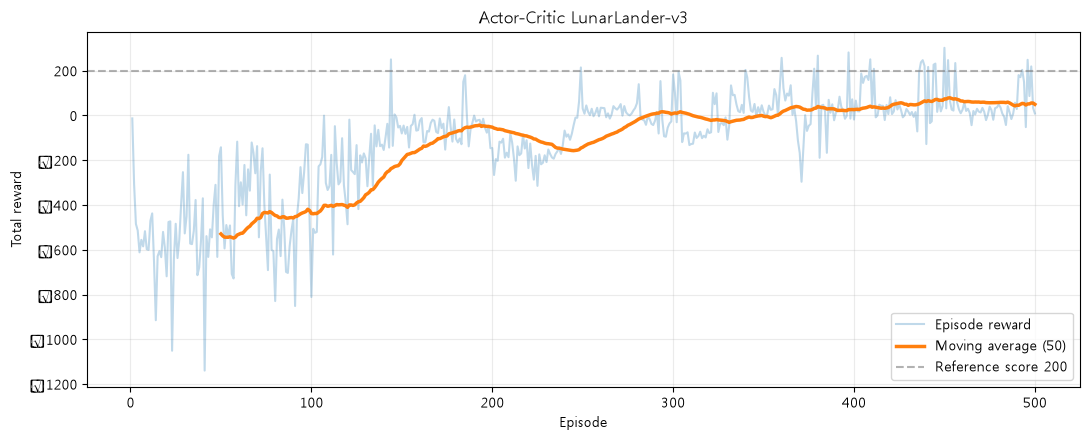

처음 50회 평균: -529.25
마지막 50회 평균: 49.86
전체 평균: -120.58
최고 에피소드 보상: 302.45
마지막 50회 평균 스텝: 261.7


In [73]:
def moving_average(values, window=50):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return np.array([]), np.array([])
    return np.arange(window, len(values)+1), np.convolve(values, np.ones(window)/window, mode="valid")

def plot_training(history, title="Actor-Critic LunarLander-v3", window=50):
    x = history["episode"].to_numpy()
    y = history["reward"].to_numpy()
    xx, yy = moving_average(y, window)
    plt.figure(figsize=(11,4.5))
    plt.plot(x, y, alpha=0.28, label="Episode reward")
    if len(xx):
        plt.plot(xx, yy, linewidth=2.5, label=f"Moving average ({window})")
    plt.axhline(200, linestyle="--", color="gray", alpha=0.6, label="Reference score 200")
    plt.xlabel("Episode"); plt.ylabel("Total reward"); plt.title(title)
    plt.legend(); plt.grid(alpha=0.25); plt.tight_layout(); plt.show()

plot_training(ac_history)
print("처음 50회 평균:", round(ac_history.reward.head(50).mean(), 2))
print("마지막 50회 평균:", round(ac_history.reward.tail(50).mean(), 2))
print("전체 평균:", round(ac_history.reward.mean(), 2))
print("최고 에피소드 보상:", round(ac_history.reward.max(), 2))
print("마지막 50회 평균 스텝:", round(ac_history.steps.tail(50).mean(), 1))

C:\Users\sdesi\AppData\Local\Temp\ipykernel_31512\2413295986.py:7: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout(); plt.show()


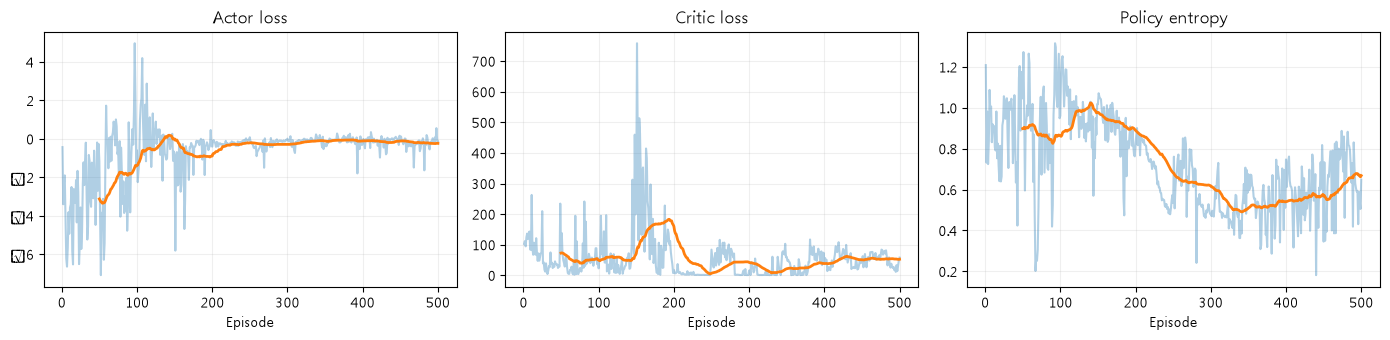

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(14,3.5))
for ax, col, title in zip(axes, ["actor_loss", "critic_loss", "entropy"], ["Actor loss", "Critic loss", "Policy entropy"]):
    ax.plot(ac_history.episode, ac_history[col], alpha=0.35)
    xx, yy = moving_average(ac_history[col], 50)
    if len(xx): ax.plot(xx, yy, linewidth=2)
    ax.set_title(title); ax.set_xlabel("Episode"); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

- 학습 중엔 확률적으로 행동 샘플링
- 학습 완료후엔 평가에서 정책 고정하고, 아래 두 방식 중 하나 선태할거임
    1. 결정적 평가 (greedy=True): logits의 argmax()로 가장 확률이 높은 행동 선택
    2. 확률적 평가 (greedy=False): Categorical에서 샘플링하여 행동 선택. 실제 학습 정책의 확률적 행동 성능 확인

```
내가 쓴 코드
def evaluate_policy(model, episodes=30, seed=1000, greedy=True, max_steps=1000):
    env = gym.make("CartPole-v3", continuous=False)
    model.eval()

    rewards = []
    steps = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        total_reward = 0.0

        for step in range(max_steps):
            x = torch.tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)

            with torch.no_grad():
                logits, _ = model(x)

                if greedy:
                    action = logits.argmax(dim=-1).item()
                else:
                    dist = Categorical(logits=logits)
                    action = dist.sample().item()


            next_state, reward, terminated, truncated, _ = env.step(int(action))

            total_reward += float(reward)
            state = next_state

            if terminated or truncated:
                break

        rewards.append(total_reward)
        steps.append(step + 1)

    env.close()

    return {
        "mean_reward": float(np.mean(rewards)),
        "std_reward": float(np.std(rewards)),
        "mean_steps": float(np.mean(steps)),
        "success_rate": float(np.mean(np.array(rewards) >= 200))
    }
```

In [75]:
next(model.parameters()).device

device(type='cpu')

In [76]:
next(model.parameters())

Parameter containing:
tensor([[0.1689]], requires_grad=True)

In [77]:
model.training

True

In [78]:
def evaluate_policy(model, episodes=30, seed=1000, greedy=True, max_steps=1000):
    env = gym.make("LunarLander-v3", continuous=False)
    device = next(model.parameters()).device
    was_training = model.training
    model.eval()
    records = []
    try:
        for ep in range(episodes):
                state, _ = env.reset(seed=seed+ep)
                total_reward = 0.0
                last_state = None
                for t in range(max_steps):
                    x = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
                    with torch.no_grad():
                        logits = model(x)[0]
                        action = logits.argmax(dim=-1) if greedy else Categorical(logits=logits).sample()
                    state, reward, terminated, truncated, _ = env.step(int(action.item()))
                    total_reward += float(reward)
                    last_state = state
                    if terminated or truncated:
                        break
                contacts = (float(last_state[6]), float(last_state[7]) if last_state is not None else (np.nan, np.nan))
                records.append({"episode": ep+1, "reward": total_reward, "steps": t+1,
                "terminated": bool(terminated), "truncated": bool(truncated),
                "left_contact_final": contacts[0], "right_contact_final": contacts[1]})
    finally:
        env.close()
        model.train(was_training)
    return pd.DataFrame(records)

In [79]:
ac_eval = evaluate_policy(ac_model, episodes=30, seed=1000, greedy=True)

In [80]:
ac_eval.head()

,episode,reward,steps,terminated,truncated,left_contact_final,right_contact_final
0,1,42.506983,182,True,False,1.0,1.0
1,2,9.380711,179,True,False,1.0,1.0
2,3,30.242391,196,True,False,1.0,1.0
3,4,2.183221,202,True,False,1.0,1.0
4,5,51.107438,148,True,False,1.0,1.0


In [81]:
print("Actor-Critic 평가 평균:", round(ac_eval.reward.mean(), 2))
print("평가 표준편차:", round(ac_eval.reward.std(), 2))
print("평균 스텝:", round(ac_eval.steps.mean(), 1))
print("보상 200 이상 비율 (착륙 성공률과는 다름):", round((ac_eval.reward >= 200).mean(), 3))

Actor-Critic 평가 평균: 20.62
평가 표준편차: 21.39
평균 스텝: 176.4
보상 200 이상 비율 (착륙 성공률과는 다름): 0.0


### **5-7. REINFORCE 같은 환경에서 직접 구현하기**
$$
G_t=\sum_{k=t}^{T-1}\gamma^{k-t}r_{k+1}
$$

$$
L_{PG}=-\frac1T\sum_t \log\pi(a_t|s_t)\widehat G_t
$$

```
이건 내 코드

# REINFORCE 정책 신경망
class PolicyNetwork(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4, hidden=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_actions)
        )

    def forward(self, x):
        return self.net(x)

# LunarLander REINFORCE 학습
def train_reinforce(episodes=500, seed=2026, gamma=0.99, lr=3e-4, print_every=50):
    set_seed(seed)

    env = gym.make("LunarLander-v3", continuous=False)
    env.action_space.seed(seed)

    net = PolicyNetwork().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=lr)

    scores = []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)

        logps = []
        rewards = []

        for t in range(1000):
            x = torch.as_tensor(
                state, dtype=torch.float32, device=DEVICE
            ).unsqueeze(0)

            # 행동 확률 분포 생성
            dist = Categorical(logits=net(x))

            # 확률에 따라 행동 선택
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(
                int(action.item())
            )

            # 선택한 행동의 로그 확률과 보상 저장
            logps.append(dist.log_prob(action).squeeze())
            rewards.append(float(reward))

            state = next_state

            if terminated or truncated:
                break

        # 할인 누적 보상 계산
        G = torch.tensor(
            discounted_returns(rewards, gamma),
            dtype=torch.float32,
            device=DEVICE
        )

        # 보상 정규화
        if len(G) > 1:
            G = (G - G.mean()) / (G.std(unbiased=False) + 1e-8)

        # 정책 손실 계산
        loss = -(torch.stack(logps) * G).sum()

        # 역전파 및 가중치 업데이트
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scores.append(sum(rewards))

        if (ep + 1) % print_every == 0:
            print(
                f"REINFORCE {ep+1}/{episodes} | "
                f"최근 50회 평균 보상: {np.mean(scores[-50:]):.2f}"
            )

    env.close()

    return net, scores
```

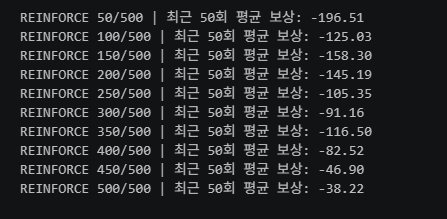

In [101]:
class PolicyNet(nn.Module):
    def __init__(self, obs_dim=8, n_actions=4, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, n_actions)
        )

    def forward(self, x):
        return self.net(x)

def discounted_returns(rewards,gamma):
    out=[]
    G = 0.0
    for r in reversed(rewards):
        G=float(r)+gamma*G
        out.append(G)
    return list(reversed(out))

In [108]:
# normalize_returns: Return을 정규화하여 학습을 안정적으로 진행하도록 설정하는 옵션
def train_reinforce(episodes=500, seed=2026, gamma=0.99, lr=3e-4, print_every=50, normalize_returns=True, hidden=128):
    set_seed(seed)
    env = gym.make("LunarLander-v3", continuous=False)
    env.action_space.seed(seed)
    model = PolicyNet(hidden=hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scores, lengths = [], []

    for ep in range(episodes):
        state, _ = env.reset(seed=seed+ep)
        rewards, log_probs = [], []

        for t in range(1000):
            x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
            logits  = model(x)
            dist = Categorical(logits=logits)
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
            log_probs.append(dist.log_prob(action).squeeze())
            rewards.append(float(reward))
            state = next_state

            if terminated or truncated:
                break

        returns = torch.as_tensor(discounted_returns(rewards, gamma), dtype=torch.float32, device=DEVICE)

        if normalize_returns and len(returns) > 1:
            returns = (returns - returns.mean()) / (returns.std(unbiased=False) + 1e-8)

        loss = -(torch.stack(log_probs) * returns).mean()

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scores.append(sum(rewards))
        lengths.append(len(rewards))
        if print_every and (ep+1) % print_every == 0:
            print(f"REINFORCE {ep+1:4d}/{episodes} | 최근 50회 평균 {np.mean(scores[-50:]):8.2f}")

    env.close()
    return model, pd.DataFrame({"episode": np.arange(1, episodes+1), "reward": scores, "steps": lengths})

In [109]:
RE_EPISODES = AC_EPISODES
re_model, re_history = train_reinforce(
    episodes=RE_EPISODES, seed=2026, gamma=0.99, lr=3e-4,
    normalize_returns=True
)
print("REINFORCE 최근 50회 평균:", round(re_history.reward.tail(50).mean(),2))

REINFORCE   50/500 | 최근 50회 평균  -183.81
REINFORCE  100/500 | 최근 50회 평균  -152.03
REINFORCE  150/500 | 최근 50회 평균  -127.07
REINFORCE  200/500 | 최근 50회 평균  -127.31
REINFORCE  250/500 | 최근 50회 평균  -176.58
REINFORCE  300/500 | 최근 50회 평균  -123.69
REINFORCE  350/500 | 최근 50회 평균  -113.01
REINFORCE  400/500 | 최근 50회 평균   -84.52
REINFORCE  450/500 | 최근 50회 평균   -70.17
REINFORCE  500/500 | 최근 50회 평균   -58.36
REINFORCE 최근 50회 평균: -58.36


```
비교용

처음 50회 평균: -529.25
마지막 50회 평균: 49.86
전체 평균: -120.58
최고 에피소드 보상: 302.45
마지막 50회 평균 스텝: 261.7
```

C:\Users\sdesi\AppData\Local\Temp\ipykernel_31512\2327329117.py:8: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.grid(alpha=0.25); plt.legend(); plt.tight_layout(); plt.show()
d:\OSA\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


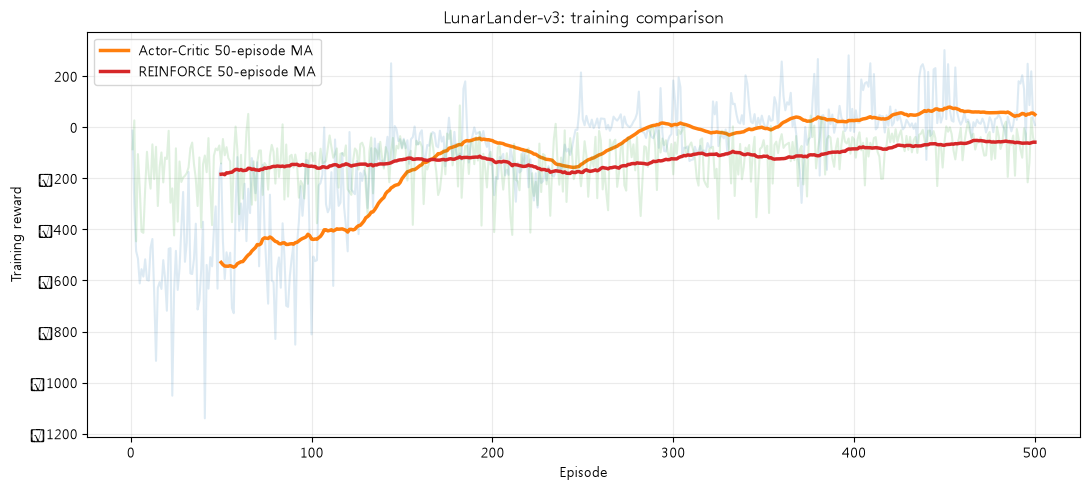

In [110]:
plt.figure(figsize=(11,5))
for name, hist in [("Actor-Critic", ac_history), ("REINFORCE", re_history)]:
    plt.plot(hist.episode, hist.reward, alpha=0.15)
    xx, yy = moving_average(hist.reward, 50)
    if len(xx): plt.plot(xx, yy, linewidth=2.5, label=f"{name} 50-episode MA")
plt.xlabel("Episode"); plt.ylabel("Training reward")
plt.title("LunarLander-v3: training comparison")
plt.grid(alpha=0.25); plt.legend(); plt.tight_layout(); plt.show()

In [111]:
re_eval = evaluate_policy(re_model, episodes=30, seed=1000, greedy=True)
comparison = pd.DataFrame({
    "algorithm": ["Random (train-time baseline)", "Actor-Critic", "REINFORCE"],
    "evaluation_mean": [np.nan, ac_eval.reward.mean(), re_eval.reward.mean()],
    "evaluation_std": [np.nan, ac_eval.reward.std(), re_eval.reward.std()],
    "last_50_training_mean": [np.nan, ac_history.reward.tail(50).mean(), re_history.reward.tail(50).mean()],
})

In [112]:
comparison

,algorithm,evaluation_mean,evaluation_std,last_50_training_mean
0,Random (train-time baseline),NaN,NaN,NaN
1,Actor-Critic,20.616359,21.394695,49.864001
2,REINFORCE,-623.319650,125.863772,-58.356529


In [113]:
# 이걸로 비교해보자
random_eval_scores = run_random_baseline(episodes=30, seed=1000)
comparison.loc[0, "evaluation_mean"] = np.mean(random_eval_scores)
comparison.loc[0, "evaluation_std"] = np.std(random_eval_scores, ddof=1)

comparison.round(2)

,algorithm,evaluation_mean,evaluation_std,last_50_training_mean
0,Random (train-time baseline),-229.32,109.42,NaN
1,Actor-Critic,20.62,21.39,49.86
2,REINFORCE,-623.32,125.86,-58.36


- 실험 A: 학습률 1e-3, e3-4, 1e-4 비교
    - 큰 학습률은 빠른 개선 또는 불안정
    - 작은 학습률은 느린 개션과 안정성
    - 실행 결과에 따라 달라질 수 있음

- 실험 B: 할인율 0.95, 0.99 비교
    - 미래의 착률 결과를 더 중요하게 생각하면 학습이 좋아질지 비교
    - 할인율이 작은 경우 먼 미래 보상이 상대적으로 빨리 할인됨
    - 할인율이 큰 경우 먼 미래 보상이 더 크게 반영됨
    - 할인율이 높을수록 학습이 잘 될 가능성 높음

- 실험 C: 엔트로피 계수 0.0, 0.01 비교
    - 정책이 너무 일찍 특정 행동 하나에 확신하지 않도록 하면 성능이 달라질지 비교
    - entropy_coef=0: 엔트로피 보너스 없음. 행동 샘플링 자체를 확률적
    - entropy_coef=0.01: 높은 엔트로피에 약한 보상을 줌
        - 엔트로피를 주는게 좋은 보상은 아님(추후 성능이 더 떨어질 수 있음)
    = 실행 결과에 따라 달라질 수 있음

In [115]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 모든 실험에서 동일하게 사용
EPISODES = 500
EVAL_EPISODES = 30
SEED = 2026

SAVE_DIR = Path("ac_experiments")
SAVE_DIR.mkdir(exist_ok=True)

BASE = {
    "lr": 3e-4,
    "gamma": 0.99,
    "entropy_coef": 0.0
}

def run_experiment(name, **params):
    history_path = SAVE_DIR / f"{name}_history.csv"
    eval_path = SAVE_DIR / f"{name}_eval.csv"

    # 이미 완료한 실험이면 저장된 결과 사용
    if history_path.exists() and eval_path.exists():
        print(f"{name}: 저장된 결과 불러오기")
        history = pd.read_csv(history_path)
        evaluation = pd.read_csv(eval_path)

    else:
        print(f"\n===== {name} 학습 시작 =====")

        model, history = train_actor_critic(
            episodes=EPISODES,
            seed=SEED,
            print_every=50,
            **params
        )

        history.to_csv(history_path, index=False)
        print(f"{name}: 학습 기록 저장 완료")

        evaluation = evaluate_policy(
            model,
            episodes=EVAL_EPISODES,
            seed=1000,
            greedy=True
        )

        evaluation.to_csv(eval_path, index=False)
        print(f"{name}: 평가 결과 저장 완료")

    return history, evaluation


def compare_experiments(title, settings):
    rows = []

    plt.figure(figsize=(9, 4))

    for name, params in settings.items():
        history, evaluation = run_experiment(name, **params)

        # 최근 20회 평균 학습 보상
        moving_avg = history["reward"].rolling(
            20, min_periods=20
        ).mean()

        plt.plot(
            history["episode"],
            moving_avg,
            label=name
        )

        rows.append({
            "실험": name,
            "학습 마지막 50회 평균": history["reward"].tail(50).mean(),
            "평가 평균 보상": evaluation["reward"].mean(),
            "평가 표준편차": evaluation["reward"].std(ddof=0)
        })

    plt.title(title)
    plt.xlabel("Episode")
    plt.ylabel("20-Episode Average Reward")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    result = pd.DataFrame(rows)
    display(result.round(2))

    return result



===== lr_1e-3 학습 시작 =====
Actor-Critic   50/500 | 최근 50회 평균  -374.20 | 이번 보상  -121.27 | 35s
Actor-Critic  100/500 | 최근 50회 평균  -138.24 | 이번 보상  -112.68 | 59s
Actor-Critic  150/500 | 최근 50회 평균  -136.18 | 이번 보상   -32.77 | 82s
Actor-Critic  200/500 | 최근 50회 평균  -122.42 | 이번 보상  -132.83 | 108s
Actor-Critic  250/500 | 최근 50회 평균  -130.90 | 이번 보상  -152.01 | 148s
Actor-Critic  300/500 | 최근 50회 평균  -126.89 | 이번 보상  -166.97 | 186s
Actor-Critic  350/500 | 최근 50회 평균  -142.91 | 이번 보상   -90.44 | 215s
Actor-Critic  400/500 | 최근 50회 평균  -151.68 | 이번 보상  -138.92 | 226s
Actor-Critic  450/500 | 최근 50회 평균  -131.09 | 이번 보상  -187.92 | 241s
Actor-Critic  500/500 | 최근 50회 평균  -187.30 | 이번 보상  -174.41 | 265s
lr_1e-3: 학습 기록 저장 완료
lr_1e-3: 평가 결과 저장 완료

===== baseline 학습 시작 =====
Actor-Critic   50/500 | 최근 50회 평균  -529.25 | 이번 보상  -142.07 | 23s
Actor-Critic  100/500 | 최근 50회 평균  -437.89 | 이번 보상  -811.05 | 48s
Actor-Critic  150/500 | 최근 50회 평균  -201.38 | 이번 보상   -80.24 | 84s
Actor-Critic  200/500 | 최근 50회 평균   -5

d:\OSA\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


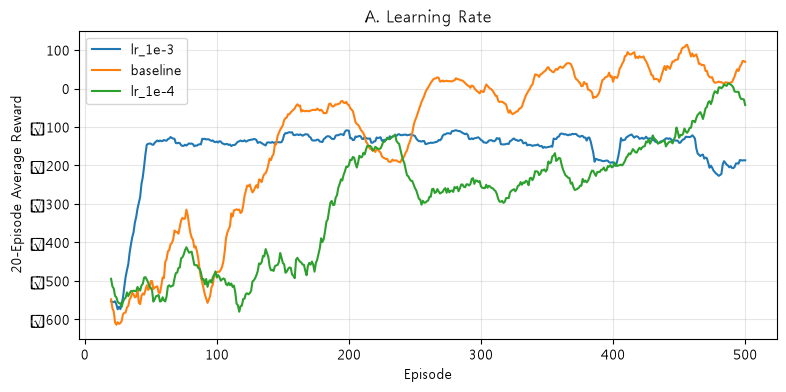

,실험,학습 마지막 50회 평균,평가 평균 보상,평가 표준편차
0,lr_1e-3,-187.30,-148.37,35.82
1,baseline,49.86,20.62,21.04
2,lr_1e-4,-33.06,-259.28,180.64


In [117]:
# 실험 A: 학습률 비교
result_A = compare_experiments(
    "A. Learning Rate",
    {
        "lr_1e-3": {**BASE, "lr": 1e-3},
        "baseline": BASE,
        "lr_1e-4": {**BASE, "lr": 1e-4}
    }
)



===== gamma_0.95 학습 시작 =====
Actor-Critic   50/500 | 최근 50회 평균  -466.34 | 이번 보상  -125.48 | 34s
Actor-Critic  100/500 | 최근 50회 평균  -148.81 | 이번 보상  -175.45 | 196s
Actor-Critic  150/500 | 최근 50회 평균   -55.00 | 이번 보상   -34.82 | 422s
Actor-Critic  200/500 | 최근 50회 평균    19.46 | 이번 보상  -158.88 | 649s
Actor-Critic  250/500 | 최근 50회 평균   -89.45 | 이번 보상   -91.65 | 914s
Actor-Critic  300/500 | 최근 50회 평균   -94.26 | 이번 보상  -160.61 | 1206s
Actor-Critic  350/500 | 최근 50회 평균  -128.38 | 이번 보상   -63.69 | 1431s
Actor-Critic  400/500 | 최근 50회 평균  -122.33 | 이번 보상   -76.75 | 1638s
Actor-Critic  450/500 | 최근 50회 평균  -125.67 | 이번 보상   -98.67 | 1891s
Actor-Critic  500/500 | 최근 50회 평균  -157.47 | 이번 보상   -83.76 | 2161s
gamma_0.95: 학습 기록 저장 완료
gamma_0.95: 평가 결과 저장 완료
baseline: 저장된 결과 불러오기


d:\OSA\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


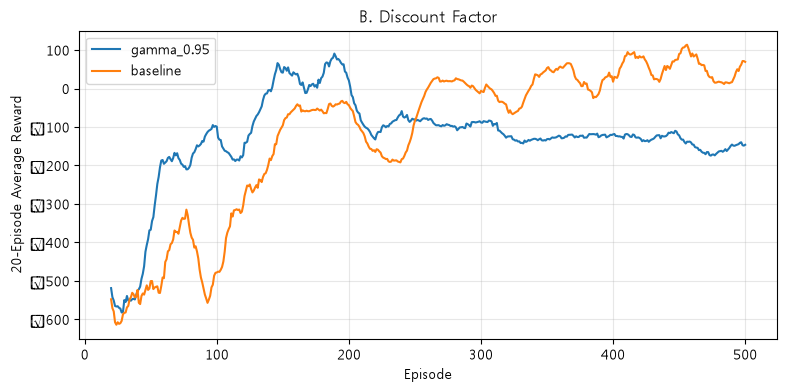

,실험,학습 마지막 50회 평균,평가 평균 보상,평가 표준편차
0,gamma_0.95,-157.47,-107.30,38.63
1,baseline,49.86,20.62,21.04


In [118]:
# 실험 B: 할인율 비교
result_B = compare_experiments(
    "B. Discount Factor",
    {
        "gamma_0.95": {**BASE, "gamma": 0.95},
        "baseline": BASE
    }
)

baseline: 저장된 결과 불러오기

===== entropy_0.01 학습 시작 =====
Actor-Critic   50/500 | 최근 50회 평균  -511.45 | 이번 보상  -409.48 | 57s
Actor-Critic  100/500 | 최근 50회 평균  -308.33 | 이번 보상  -295.92 | 91s
Actor-Critic  150/500 | 최근 50회 평균  -104.36 | 이번 보상  -143.70 | 181s
Actor-Critic  200/500 | 최근 50회 평균  -103.29 | 이번 보상  -161.89 | 352s
Actor-Critic  250/500 | 최근 50회 평균  -112.53 | 이번 보상   -44.79 | 671s
Actor-Critic  300/500 | 최근 50회 평균   -10.70 | 이번 보상   -46.12 | 946s
Actor-Critic  350/500 | 최근 50회 평균    51.04 | 이번 보상   184.02 | 1229s
Actor-Critic  400/500 | 최근 50회 평균    72.04 | 이번 보상   -29.34 | 1358s
Actor-Critic  450/500 | 최근 50회 평균   117.34 | 이번 보상   -28.68 | 1531s
Actor-Critic  500/500 | 최근 50회 평균   -15.46 | 이번 보상    -5.89 | 1713s
entropy_0.01: 학습 기록 저장 완료
entropy_0.01: 평가 결과 저장 완료


d:\OSA\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


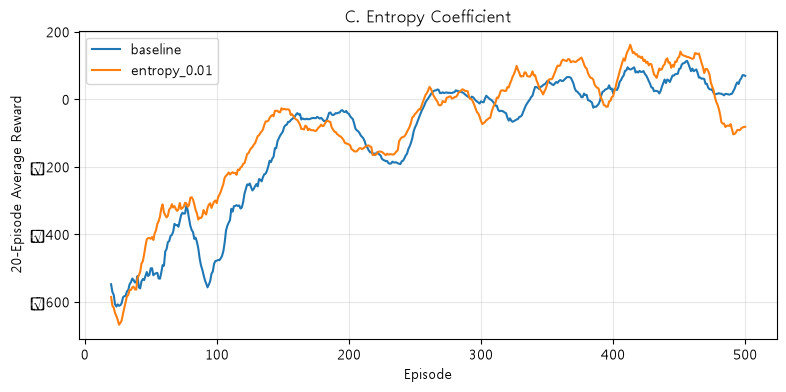

,실험,학습 마지막 50회 평균,평가 평균 보상,평가 표준편차
0,baseline,49.86,20.62,21.04
1,entropy_0.01,-15.46,-23.74,20.10


In [120]:
# 실험 C: 엔트로피 계수 비교
result_C = compare_experiments(
    "C. Entropy Coefficient",
    {
        "baseline": BASE,
        "entropy_0.01": {**BASE, "entropy_coef": 0.01}
    }
)

### 실제 실험결과

#### 실험A. 학습률 비교
```
학습률      | 평가 평균 보상
0.001      | -148.37
0.0003     | 20.62
0.0001     | -259.28
```
- 학습률이 0.001일 때는 초반에 빠르게 개선되었지만, 최종 평가 성능은 안좋음
- 학습률이 0.0001일 때는 학습 개선 속도가 느리고, 가장 낮은 평가 보상을 기록
- 0.0003에서 가장 높은 평가 보상을 기록
> 학습률이 크거나 작다고 무조건 좋은 것이 아니라, 적절한 학습률을 선택하는 것이 중요하다는 것 확인됨

#### 실험B. 할인율(Gamma) 비교
```
할인율       | 평가 평균 보상
0.95        | -107.30
0.99        | 20.62
```
- 할인율이 0.95일 때는 낮은 평가 보상을 기록
- 할인율이 0.99일 때는 0.95보다 높은 평가 보상을 기록
- 할인율이 높을수록 미래 보상을 더 크게 반영하며, 이번 실험에서는 0.99가 더 좋은 결과를 보임

> 이번 실험에서는 미래 보상을 더 중요하게 고려하는 할인율 0.99가 유리하다는 것 확인됨

#### 실험C. 엔트로피 계수 비교
```
엔트로피 계수   | 평가 평균 보상
0             | 20.62
0.01          | -23.74
```
- 엔트로피 계수가 0일 때 가장 높은 평가 보상을 기록
- 엔트로피 계수가 0.01일 때는 오히려 평가 보상이 낮아짐
- 엔트로피 보너스는 다양한 행동을 탐색하도록 유도하지만, 반드시 성능 향상으로 이어지는 것은 아님

> 이번 실험에서는 엔트로피 보너스를 추가하지 않은 설정이 더 좋은 결과를 보였으며, 탐색을 늘린다고 무조건 성능이 좋아지는 것은 아니라는 것 확인됨